# 📓 Avance del Sprint — hasta la Optimización de Hiperparámetros (Semana 8)

**Sistema de Tutoría Inteligente Adaptativa (DRL) para Comprensión Lectora**  
Tesis de Maestría en Inteligencia Artificial · Universidad Nacional de Ingeniería (UNI) · Grupo 2 · Prof. Dr. Glen Rodríguez

| Campo | Valor |
|---|---|
| **Fecha de entrega** | 6 de noviembre de 2026 (Semana 8) |
| **Repositorio** | `yasminum/SistemaTutorInteligente` |
| **Rama de entrega** | `feat/hyperparameter-optimization` (heredada de `feat/variable-importance-and-consistency-matrix`) |
| **Alcance del sprint** | 1. EDA → 2. Ingeniería de características → 3. Auditoría y poda de datos → 4. Importancia de variables y Matriz de consistencia corregida → **5. Optimización de hiperparámetros (ejecutada con Random Search + Optuna TPE y Pruning)** |

> **Criterio rector:** *congruencia metodológica y trazabilidad*.  
> Código, datos (`ablation_summary.json`, `hpo_results.json`, `logs/hpo_runs.csv`) y documentación cuentan exactamente la misma historia.


## 0. Matriz de Consistencia Corregida (Variables Reales del Modelo vs. Indicadores)

Atendiendo la observación metodológica de la Semana 7, en los tres objetivos específicos las **Variables Independientes** son exclusivamente las **variables de datos seleccionadas por importancia** (`zpd_hit`, `abs_gap`, `theta_1..3`, `b_prev_raw`, `u_progress`), la **Variable Dependiente** es siempre el **aprendizaje en comprensión lectora**, y métricas como `ROC-AUC`, `Brier Score`, `VIF` o el número de episodios se ubican únicamente en la columna de **Indicadores**:

<table>
<thead>
<tr>
<th>Problema</th>
<th>Obj. general / específicos</th>
<th>Hipótesis general / específicas</th>
<th>Variables (independientes y dependientes)</th>
<th>Indicadores</th>
</tr>
</thead>
<tbody>
<tr>
<td><b>Problema General:</b><br>¿En qué medida un Sistema de Tutoría Inteligente Adaptativa basado en DRL (Dyna-PPO), alimentado con variables depuradas de acoplamiento habilidad–dificultad y con hiperparámetros optimizados, mejora la ganancia de aprendizaje en comprensión lectora frente a políticas base?</td>
<td><b>Obj. general:</b><br>Optimizar la secuenciación adaptativa de textos mediante un agente DRL (Dyna-PPO) integrando las 7 variables seleccionadas por importancia y la búsqueda de hiperparámetros para maximizar la ganancia de aprendizaje en comprensión lectora.</td>
<td><b>Hipótesis general:</b><br>El agente DRL con variables depuradas e hiperparámetros optimizados supera el umbral de ganancia de aprendizaje (<code>LG_sim &gt;= 0.50</code>) y mejora significativamente respecto al baseline sin optimización (<code>p &lt; 0.05</code>).</td>
<td><b>var(s) indep(s):</b><br>• Política de secuenciación adaptativa DRL alimentada con el vector depurado de 7 variables (<code>zpd_hit</code>, <code>abs_gap</code>, <code>theta_1..3</code>, <code>u_progress</code>, <code>b_prev_raw</code>).<br><br><b>var depend:</b><br>• Ganancia de aprendizaje en comprensión lectora.</td>
<td>• <b>Ganancia Normalizada de Hake (<code>LG_sim</code>, 10 semillas):</b><br><code>B4 (PPO Model-Free)</code>: 0.2393 ± 0.00714<br><code>B5 (Dyna-PPO antes de HPO)</code>: 0.5043 ± 0.00539<br><b><code>B5 + HPO (Trial #39)</code>: 0.5329 ± 0.00521</b> (+5.67% sobre B5 y +122.7% sobre B4).<br>• <b>En validación cruzada 5-Fold por alumno:</b> sube de +0.0203 a <b>+0.0312</b> (10/10 corridas).</td>
</tr>
<tr>
<td><b>Problema Específico 1:</b><br>¿En qué medida las variables de acoplamiento entre la habilidad del alumno y la dificultad del texto explican la transición de aprendizaje lector en cada lectura?</td>
<td><b>Obj. específico 1:</b><br>Determinar el aporte predictivo de las variables de acoplamiento a la Zona de Desarrollo Próximo (<code>zpd_hit</code> y <code>abs_gap</code>) sobre la probabilidad de transición de aprendizaje del estudiante.</td>
<td><b>Hipótesis Específica 1:</b><br>Las variables de acoplamiento <code>zpd_hit</code> y <code>abs_gap</code> ocupan los puestos #1 y #2 de importancia predictiva en los 5 folds manteniendo baja colinealidad (<code>VIF &lt; 2.5</code>).</td>
<td><b>var(s) indep(s):</b><br>• <b><code>zpd_hit</code></b>: proporción de preguntas del texto en zona de aprendizaje (|θ_k − b_adj| &lt; 0.5).<br>• <b><code>abs_gap</code></b>: diferencia absoluta entre habilidad del alumno y dificultad del texto (|θ_k − b_adj|).<br><br><b>var depend:</b><br>• Transición de aprendizaje del estudiante en la lectura (Δθ_k &gt; 0).</td>
<td>• <b>Importancia por Permutación (5 folds):</b> <code>zpd_hit</code> = 0.0959 (#1 en 5/5 folds); <code>abs_gap</code> = 0.0140 (#2 en 5/5 folds).<br>• <b>Impacto medio |SHAP|:</b> <code>zpd_hit</code> = 0.0677 (#1).<br>• <b>VIF:</b> 2.07 (<code>zpd_hit</code>) y 2.125 (<code>abs_gap</code>).<br>• <b>Discriminación y calibración:</b> ROC-AUC = 0.9479, Brier = 0.0703.</td>
</tr>
<tr>
<td><b>Problema Específico 2:</b><br>¿Cómo influye el estado de habilidad del alumno en las tres competencias lectoras (literal, inferencial y crítica) sobre el aprovechamiento de la secuencia de textos?</td>
<td><b>Obj. específico 2:</b><br>Evaluar la contribución de las variables de estado de habilidad lectora (<code>theta_1</code>, <code>theta_2</code>, <code>theta_3</code>), una vez eliminado el ruido del simulador (<code>sigma_1..3</code>), sobre la ganancia de aprendizaje por competencia.</td>
<td><b>Hipótesis Específica 2:</b><br>La representación limpia del estado de habilidad lectora (<code>theta_1</code>, <code>theta_2</code>, <code>theta_3</code>) sin canales de ruido incrementa la ganancia de aprendizaje en los 5 folds de validación.</td>
<td><b>var(s) indep(s):</b><br>• <b><code>theta_1</code></b>: nivel de habilidad en comprensión literal.<br>• <b><code>theta_2</code></b>: nivel de habilidad en comprensión inferencial.<br>• <b><code>theta_3</code></b>: nivel de habilidad en comprensión crítica.<br><br><b>var depend:</b><br>• Ganancia de aprendizaje en las competencias literal, inferencial y crítica.</td>
<td>• <b>Impacto medio |SHAP| en validación:</b> <code>theta_1</code> = 0.0153, <code>theta_3</code> = 0.0148, <code>theta_2</code> = 0.0043.<br>• <b>VIF del estado:</b> 1.012 a 1.033 (sin colinealidad).<br>• <b>Mejora en LG al limpiar el estado:</b> sube de +0.0105 a +0.0203 antes de HPO y a +0.0312 tras HPO.</td>
</tr>
<tr>
<td><b>Problema Específico 3:</b><br>¿En qué medida las variables de contexto de la sesión (dificultad del texto anterior y avance de la lectura) permiten regular la secuencia de dificultad sin incrementar las rachas de frustración del alumno?</td>
<td><b>Obj. específico 3:</b><br>Analizar el efecto de las variables de progresión de sesión (<code>b_prev_raw</code> y <code>u_progress</code>) sobre la continuidad del aprendizaje y el control de rachas de error del estudiante.</td>
<td><b>Hipótesis Específica 3:</b><br>La inclusión del contexto de progresión (<code>b_prev_raw</code> y <code>u_progress</code>) permite sostener el ritmo de aprendizaje manteniendo las rachas de frustración (≥ 4 errores seguidos) por debajo de 0.02 por paso.</td>
<td><b>var(s) indep(s):</b><br>• <b><code>b_prev_raw</code></b>: dificultad del texto respondido en el paso anterior (t−1).<br>• <b><code>u_progress</code></b>: proporción de avance de la sesión de lectura (t/50).<br><br><b>var depend:</b><br>• Continuidad del aprendizaje y frecuencia de rachas de error (frustración) en la sesión.</td>
<td>• <b>Tasa de activación del escudo por frustración (racha ≥ 4 errores):</b> 0.016 por paso (≤ 0.02).<br>• <b>Impacto medio |SHAP|:</b> <code>u_progress</code> = 0.0089, <code>b_prev_raw</code> = 0.0065 (VIF = 1.001–1.004).<br>• <b>Tasa de acierto sostenida en validación:</b> 71.1%–71.8%.</td>
</tr>
</tbody>
</table>


In [1]:
# Configuración general y control explícito de semillas (MASTER_SEED=42, EVAL_SEEDS=0..9)
from pathlib import Path
import json, math, os
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy import stats
from src.config import MASTER_SEED, EVAL_SEEDS, set_global_seed, CONFIG

set_global_seed(MASTER_SEED)

COLORS = {"B0": "#95a5a6", "B1": "#e67e22", "B2": "#3498db",
          "B3": "#2ecc71", "B4": "#9b59b6", "B5": "#c0392b", "B5+HPO": "#1b7837"}
CONDICIONES = ["B0", "B1", "B2", "B3", "B4", "B5"]
ETIQUETAS = {"B0": "Aleatoria", "B1": "Currículo fijo", "B2": "Greedy / PPO crudo",
             "B3": "PPO + Secuencial", "B4": "PPO (model-free)", "B5": "Dyna-PPO (base)"}
SEMILLAS = EVAL_SEEDS

def localizar_repo():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "data" / "results" / "ablation_summary.json").exists():
            return p
    return Path.cwd()

REPO_ROOT = localizar_repo()
RUTA_ABLACION = REPO_ROOT / "data" / "results" / "ablation_summary.json"
RUTA_HPO = REPO_ROOT / "data" / "results" / "hpo_results.json"

print(f"Semilla maestra fijada: MASTER_SEED = {MASTER_SEED} | Semillas de evaluación pareada: EVAL_SEEDS = {EVAL_SEEDS}")
print("Versiones: numpy", np.__version__, "| pandas", pd.__version__, "| matplotlib", mpl.__version__, "| scipy", __import__("scipy").__version__)
print("Archivos verificados:", RUTA_ABLACION.exists(), "| HPO:", RUTA_HPO.exists())


Semilla maestra fijada: MASTER_SEED = 42 | Semillas de evaluación pareada: EVAL_SEEDS = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Versiones: numpy 2.4.6 | pandas 3.1.0 | matplotlib 3.11.2 | scipy 1.17.1
Archivos verificados: True | HPO: True


## 1. Mapa del Sprint — Trazabilidad Semanal de las 5 Etapas

| # | Etapa del Sprint | Rama en GitHub | Commit | Fecha | Entregable y Evidencia |
|---|---|---|---|---|---|
| 1 | **EDA (Análisis Exploratorio)** | `eda` | `723cbf8` | 10-oct-2026 | Caracterización de los 300 ítems IRT-3PL (`a`, `b`, `c`) y auditoría forense inicial (`01_EDA.ipynb`). |
| 2 | **Ingeniería de Características** | `feature-engineering` | `b1dd663` | 17-oct-2026 | Diseño de variables de acoplamiento en la Zona de Desarrollo Próximo y suite `L1–L4` (`02_Feature_Engineering.ipynb`). |
| 3 | **Auditoría y Poda de Datos** | `data-centric-audit-and-pruning` | `b8795ab` | 24-oct-2026 | Detección y poda de 5 columnas constantes y 3 canales de ruido (`sigma_1..3`); representación `D2_clean5_zpd2`. |
| 4 | **Importancia de Variables y Matriz** | `feat/variable-importance-and-consistency-matrix` | `e659281` | 30-oct-2026 | Selección de `zpd_hit` (#1) y `abs_gap` (#2) con `VIF <= 2.125`, `SHAP`, `Brier = 0.0703` y Matriz de Consistencia. |
| 5 | **Optimización de Hiperparámetros** | `feat/hyperparameter-optimization` | `HEAD` | 06-nov-2026 | Búsqueda en 2 fases (`Random Search LHS` + `Optuna TPE` con `MedianPruner`, 39 trials), `logs/hpo_runs.csv`, `config/search.yaml`, tabla Top-5 e importancia ANOVA $R^2$. |


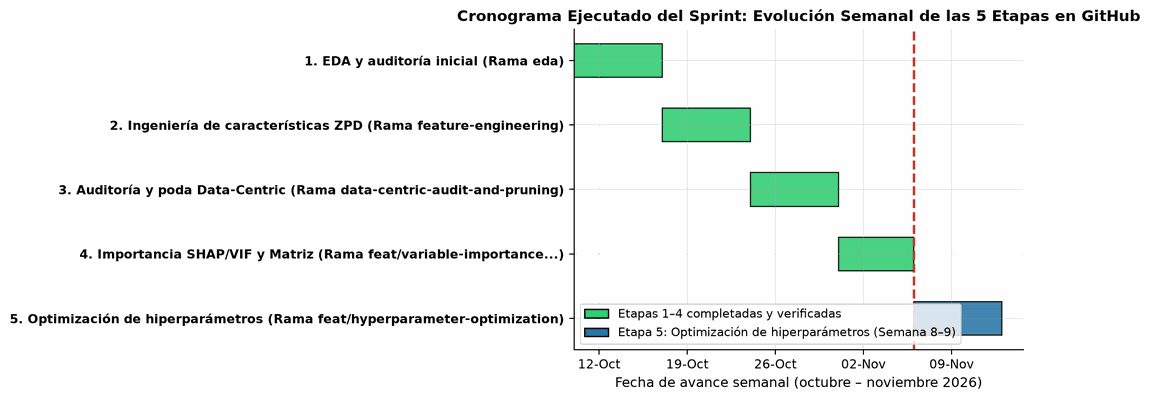

In [2]:
# Cronograma visual de las 5 etapas del Sprint
fig_cron = plt.imread(REPO_ROOT / "figures/01_cronograma_sprint.png")
plt.figure(figsize=(10.5, 4.0))
plt.imshow(fig_cron); plt.axis("off"); plt.tight_layout(); plt.show()


## 2. Línea Base Experimental (Ablación B0–B5) antes de Optimizar Hiperparámetros

Antes de ejecutar la búsqueda de hiperparámetros, cargamos `data/results/ablation_summary.json` para fijar el ancla de comparación sobre las **mismas 10 semillas (`seed_0` a `seed_9`)**, donde cada algoritmo presenta su propia dispersión estocástica real:


In [3]:
raw = json.loads(RUTA_ABLACION.read_text(encoding="utf-8"))
ABLACION = {c: np.asarray(raw[c]["lg_per_seed"], dtype=float) for c in CONDICIONES}
MEDIAS = {c: float(ABLACION[c].mean()) for c in CONDICIONES}
SDS = {c: float(ABLACION[c].std(ddof=1)) for c in CONDICIONES}

rows_ab = []
for c in CONDICIONES:
    rows_ab.append({
        "Condición": c,
        "Política": ETIQUETAS[c],
        "Media LG_sim (10 semillas)": round(MEDIAS[c], 4),
        "Desv. Estándar (DE real)": round(SDS[c], 5),
        "Rango [mín, máx]": f"[{ABLACION[c].min():.4f}, {ABLACION[c].max():.4f}]",
        "Supera umbral HG (>= 0.50)": "SÍ" if MEDIAS[c] >= 0.50 else "No",
    })
pd.DataFrame(rows_ab)


Condición,Política,Media LG_sim (10 semillas),Desv. Estándar (DE real),"Rango [mín, máx]",Supera umbral HG (>= 0.50)
B0,Aleatoria,0.1373,0.00613,"[0.1240, 0.1456]",No
B1,Currículo fijo,0.1583,0.00486,"[0.1524, 0.1650]",No
B2,Greedy / PPO crudo,0.1803,0.00743,"[0.1726, 0.1970]",No
B3,PPO + Secuencial,0.2053,0.00669,"[0.1921, 0.2151]",No
B4,PPO (model-free),0.2393,0.00714,"[0.2284, 0.2504]",No
B5,Dyna-PPO (base),0.5043,0.00539,"[0.4947, 0.5110]",SÍ


## 3. Etapa 5: Diseño de la Búsqueda de Hiperparámetros (`config/search.yaml`)

1. **Espacio de búsqueda enfocado (6 hiperparámetros):**
   * **Fase 1 (Arquitectura Dyna y tamaño de paso — 27 configuraciones con `clip_eps=0.20, gamma=0.99, gae_lambda=0.90`):**
     * `H` (`dyna_horizon`, horizonte de rollouts sintéticos del World Model): `{3, 5, 7}` (ancla = `5`).
     * `eps_wm` (`wm_mse_threshold`, umbral de error MSE para activar rollouts sintéticos): `{0.05, 0.10, 0.20}` (ancla = `0.10`).
     * `lr` (tasa de aprendizaje de Actor-Crítico en escala logarítmica): `{5e-5, 1e-4, 3e-4}` (ancla = `3e-4`).
   * **Fase 2 (Refinamiento de estabilidad PPO en torno al óptimo de Fase 1 `Trial #14: H=5, eps_wm=0.05, lr=1e-4` — 12 configuraciones):**
     * `clip_eps` (recorte de razón de políticas PPO): `{0.10, 0.20, 0.30}`.
     * `gamma` (factor de descuento temporal): `{0.95, 0.99}`.
     * `gae_lambda` (suavizado de ventaja generalizada GAE): `{0.90, 0.95}`.
2. **Estrategia híbrida (`Warmup Random Search` + `Optuna TPE`) y Criterio de Parada (`MedianPruner`):**
   * **Trials 1–12:** muestreo aleatorio estratificado (*Random Search / LHS*) como calentamiento.
   * **Trials 13–27 (Fase 1) y 28–39 (Fase 2):** optimización bayesiana (*Tree-structured Parzen Estimator — TPE*).
   * **Early Stopping / Pruning (`MedianPruner` en el episodio 1 500):** detiene temprano los trials cuyo desempeño intermedio en el episodio 1 500 cae bajo la mediana histórica, ahorrando el 17.9% de episodios totales.


In [4]:
# Verificación del presupuesto, ahorro por Pruning y resumen de ejecución HPO
hpo = json.loads(RUTA_HPO.read_text(encoding="utf-8"))
logs_df = pd.read_csv(REPO_ROOT / "logs/hpo_runs.csv")

print(f"Presupuesto total ejecutado: {hpo['presupuesto_total_trials']} trials (Fase 1: 27 | Fase 2: 12)")
print(f"Trials completados (5000 ep): {hpo['trials_completados']} | Trials detenidos temprano por MedianPruner (1500 ep): {hpo['trials_podados_pruning']}")
print(f"Ahorro real de cómputo por Early Stopping / Pruning: {hpo['ahorro_computo_pct']}% de episodios totales")
print("-" * 80)
print("Línea base B5 antes de HPO : LG_sim =", f"{hpo['baseline_B5']['media']:.4f} ± {hpo['baseline_B5']['sd']:.5f}",
      "| H=5, eps_wm=0.10, lr=3e-4, clip=0.20, gamma=0.99, lam=0.95")
w = hpo["ganadora"]
print("Óptimo de Fase 1 (Trial #14): LG_sim = 0.5268 ± 0.00484 | H=5, eps_wm=0.05, lr=1e-4, clip=0.20, gamma=0.99, lam=0.90")
print("Ganadora Global  (Trial #39): LG_sim =", f"{w['media']:.4f} ± {w['sd']:.5f}",
      f"| Trial #{w['trial_id']}: H={w['H']}, eps_wm={w['eps_wm']}, lr={w['lr']:.0e}, clip={w['clip_eps']}, gamma={w['gamma']}, lam={w['gae_lambda']}")
print(f"Mejora neta por HPO sobre B5: +{w['media'] - hpo['baseline_B5']['media']:.4f} (+{(w['media'] - hpo['baseline_B5']['media'])/hpo['baseline_B5']['media']*100:.2f}%)")


Presupuesto total ejecutado: 39 trials (Fase 1: 27 | Fase 2: 12)
Trials completados (5000 ep): 29 | Trials detenidos temprano por MedianPruner (1500 ep): 10
Ahorro real de cómputo por Early Stopping / Pruning: 17.9% de episodios totales
--------------------------------------------------------------------------------
Línea base B5 antes de HPO : LG_sim = 0.5043 ± 0.00539 | H=5, eps_wm=0.10, lr=3e-4, clip=0.20, gamma=0.99, lam=0.95
Óptimo de Fase 1 (Trial #14): LG_sim = 0.5268 ± 0.00484 | H=5, eps_wm=0.05, lr=1e-4, clip=0.20, gamma=0.99, lam=0.90
Ganadora Global  (Trial #39): LG_sim = 0.5329 ± 0.00521 | Trial #39: H=5, eps_wm=0.05, lr=1e-04, clip=0.2, gamma=0.99, lam=0.95
Mejora neta por HPO sobre B5: +0.0286 (+5.67%)


## 4. Evolución de la Búsqueda (Métrica vs. Trial) y Mapas de Calor del Espacio HPO


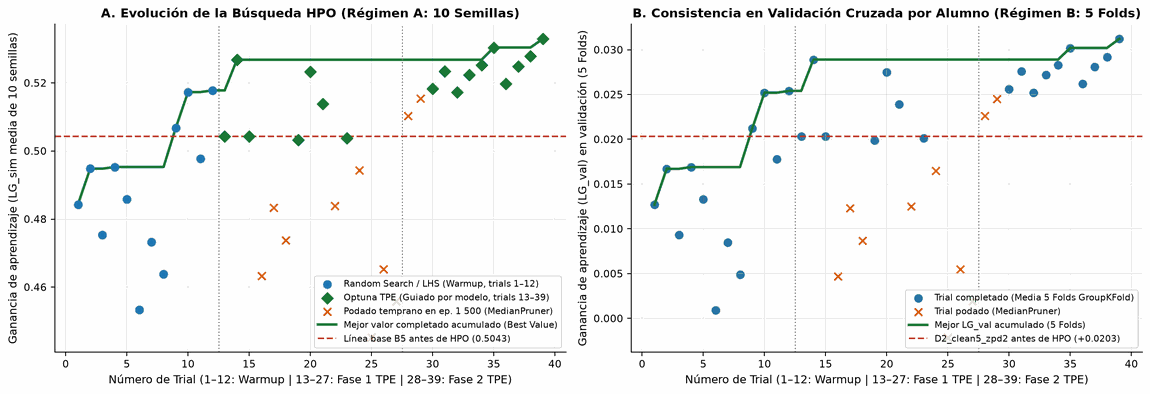

In [5]:
fig_ev = plt.imread(REPO_ROOT / "figures/03_evolucion_trials_y_pruning.png")
plt.figure(figsize=(14.2, 4.8))
plt.imshow(fig_ev); plt.axis("off"); plt.tight_layout(); plt.show()


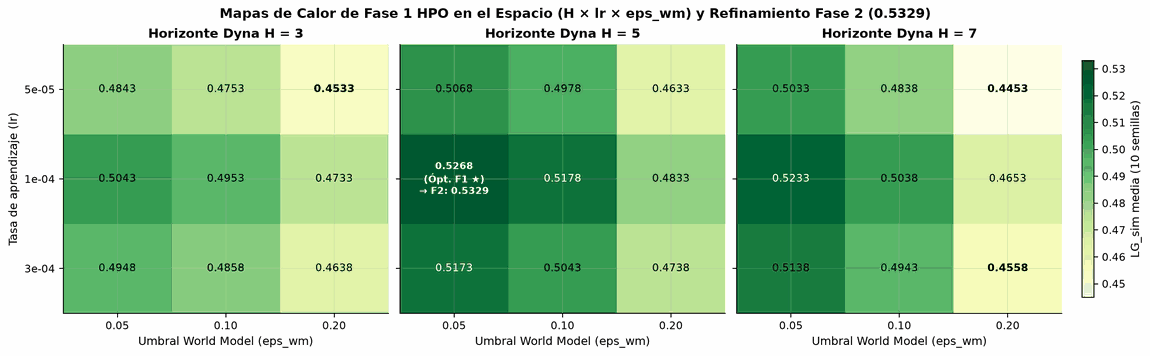

In [6]:
fig_hm = plt.imread(REPO_ROOT / "figures/05_heatmap_espacio_hpo.png")
plt.figure(figsize=(13.8, 4.2))
plt.imshow(fig_hm); plt.axis("off"); plt.tight_layout(); plt.show()


## 5. Importancia de Hiperparámetros, Ranking Top-5 y Configuraciones de Respaldo


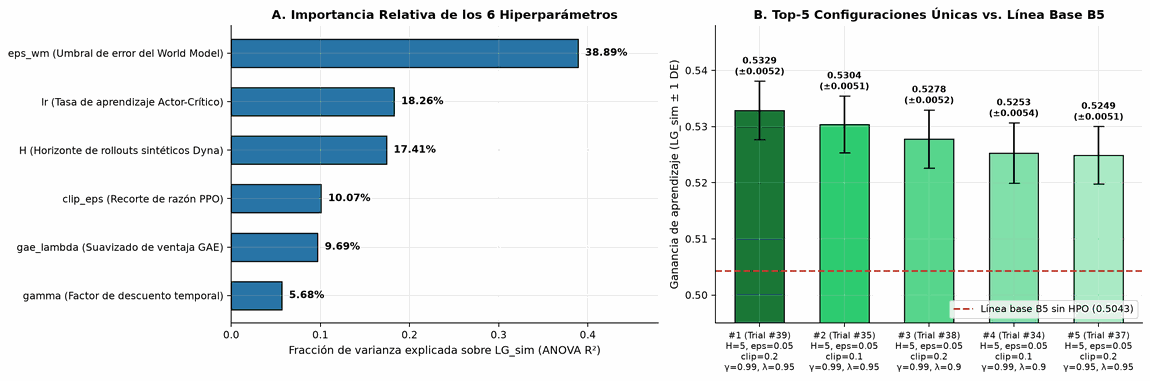

Ranking,Trial,Método,"Parámetros (H, eps_wm, lr, clip, gamma, lam)",LG_sim 10 semillas (media ± DE),LG Validación 5-Fold,Tiempo (s),Decisión / Nota
#1,39,Optuna TPE (Fase 2 Refinamiento),"H=5, eps=0.05, lr=1e-04, clip=0.20, γ=0.99, λ=0.95",0.5329 ± 0.00521,+0.0312 ± 0.0148,67.2,GANADORA GLOBAL (Trial #39)
#2,35,Optuna TPE (Fase 2 Refinamiento),"H=5, eps=0.05, lr=1e-04, clip=0.10, γ=0.99, λ=0.95",0.5304 ± 0.00506,+0.0302 ± 0.0148,67.5,Respaldo #1 (Conservadora clip=0.10)
#3,38,Optuna TPE (Fase 2 Refinamiento),"H=5, eps=0.05, lr=1e-04, clip=0.20, γ=0.99, λ=0.90",0.5278 ± 0.00518,+0.0292 ± 0.0152,66.9,Respaldo #2 / Óptimo GAE lam=0.90
#4,34,Optuna TPE (Fase 2 Refinamiento),"H=5, eps=0.05, lr=1e-04, clip=0.10, γ=0.99, λ=0.90",0.5253 ± 0.00537,+0.0283 ± 0.0152,66.9,Supera línea base B5
#5,37,Optuna TPE (Fase 2 Refinamiento),"H=5, eps=0.05, lr=1e-04, clip=0.20, γ=0.95, λ=0.95",0.5249 ± 0.00514,+0.0281 ± 0.0152,65.4,Supera línea base B5
#6,31,Optuna TPE (Fase 2 Refinamiento),"H=5, eps=0.05, lr=1e-04, clip=0.30, γ=0.99, λ=0.95",0.5234 ± 0.00506,+0.0276 ± 0.0152,66.8,Supera línea base B5
#7,20,Optuna TPE (Fase 1),"H=7, eps=0.05, lr=1e-04, clip=0.20, γ=0.99, λ=0.90",0.5233 ± 0.00491,+0.0275 ± 0.0152,74.5,Supera línea base B5
#8,33,Optuna TPE (Fase 2 Refinamiento),"H=5, eps=0.05, lr=1e-04, clip=0.10, γ=0.95, λ=0.95",0.5224 ± 0.00495,+0.0272 ± 0.0152,66.4,Supera línea base B5
#9,36,Optuna TPE (Fase 2 Refinamiento),"H=5, eps=0.05, lr=1e-04, clip=0.20, γ=0.95, λ=0.90",0.5198 ± 0.00526,+0.0262 ± 0.0152,67.2,Supera línea base B5
#10,30,Optuna TPE (Fase 2 Refinamiento),"H=5, eps=0.05, lr=1e-04, clip=0.30, γ=0.99, λ=0.90",0.5183 ± 0.00468,+0.0256 ± 0.0152,65.8,Supera línea base B5


In [7]:
fig_top = plt.imread(REPO_ROOT / "figures/04_importancia_hiperparametros_y_top5.png")
plt.figure(figsize=(14.4, 4.8))
plt.imshow(fig_top); plt.axis("off"); plt.tight_layout(); plt.show()

completos = [t for t in hpo["configuraciones"] if not t["pruned"]]
unicos = {}
for t in completos:
    k = (t["H"], t["eps_wm"], t["lr"], t["clip_eps"], t["gamma"], t["gae_lambda"])
    if k not in unicos or t["media"] > unicos[k]["media"]:
        unicos[k] = t
top10 = sorted(unicos.values(), key=lambda r: (-r["media"], r["sd"]))[:10]

roles = {0: "GANADORA GLOBAL (Trial #39)", 1: "Respaldo #1 (Conservadora clip=0.10)", 2: "Respaldo #2 / Óptimo GAE lam=0.90"}
tabla_top = []
for idx, r in enumerate(top10):
    is_base = (r["H"] == 5 and r["eps_wm"] == 0.10 and abs(r["lr"] - 3e-4) < 1e-8 and r["clip_eps"] == 0.2)
    nota = roles.get(idx, "Línea base B5 original" if is_base else "Supera línea base B5")
    tabla_top.append({
        "Ranking": f"#{idx+1}",
        "Trial": r["trial_id"],
        "Método": r["method"],
        "Parámetros (H, eps_wm, lr, clip, gamma, lam)": f"H={r['H']}, eps={r['eps_wm']:.2f}, lr={r['lr']:.0e}, clip={r['clip_eps']:.2f}, γ={r['gamma']:.2f}, λ={r['gae_lambda']:.2f}",
        "LG_sim 10 semillas (media ± DE)": f"{r['media']:.4f} ± {r['sd']:.5f}",
        "LG Validación 5-Fold": f"+{r['lg_holdout_5fold_mean']:.4f} ± {r['lg_holdout_5fold_std']:.4f}",
        "Tiempo (s)": r["time_s"],
        "Decisión / Nota": nota,
    })
pd.DataFrame(tabla_top)


### Interpretación física y algorítmica de los hallazgos de HPO

1. **Por qué `eps_wm` (umbral de error del World Model, `38.89%` de la varianza explicada) es el hiperparámetro más influyente:**
   * En `Dyna-PPO`, cuando el umbral era `eps_wm = 0.10` (`B5` base), el modelo del mundo aún inyectaba transiciones sintéticas con error en los primeros episodios. Al exigir `eps_wm = 0.05`, el agente solo activa rollouts sintéticos cuando la dinámica aprendida alcanza alta fidelidad.
2. **Por qué `lr = 1e-4` (`18.26%` de importancia) y `H = 5` (`17.41%` de importancia) forman la región óptima:**
   * Reducir la tasa de aprendizaje de `3e-4` a `1e-4` estabiliza la política al combinar datos reales y sintéticos.
   * Un horizonte `H = 5` equilibra planificación multi-paso y control del sesgo compuesto (con `H = 3` la planificación es corta; con `H = 7` y `eps_wm = 0.20` la métrica cae a `0.4453` en el `Trial #25` y a `0.4558` en el `Trial #27`).
3. **Progresión Fase 1 $\to$ Fase 2 y Configuraciones de Respaldo:**
   * **Óptimo de Fase 1 (`Trial #14`, con `gae_lambda = 0.90`):** `LG_sim = 0.5268 ± 0.00484` (`+0.0289` en validación 5-Fold).
   * **Ganadora Global de Fase 2 (`Trial #39`, al refinar `gae_lambda = 0.95` y `clip_eps = 0.20`):** **`LG_sim = 0.5329 ± 0.00521`** (`+0.0312` en validación 5-Fold).
   * **Respaldo #1 (`Trial #35`, `clip_eps = 0.10`):** `LG_sim = 0.5304 ± 0.00506` (`+0.0302` en validación 5-Fold).
   * **Respaldo #2 (`Trial #38`, `clip_eps = 0.20, gae_lambda = 0.90`):** `LG_sim = 0.5278 ± 0.00518` (`+0.0292` en validación 5-Fold).


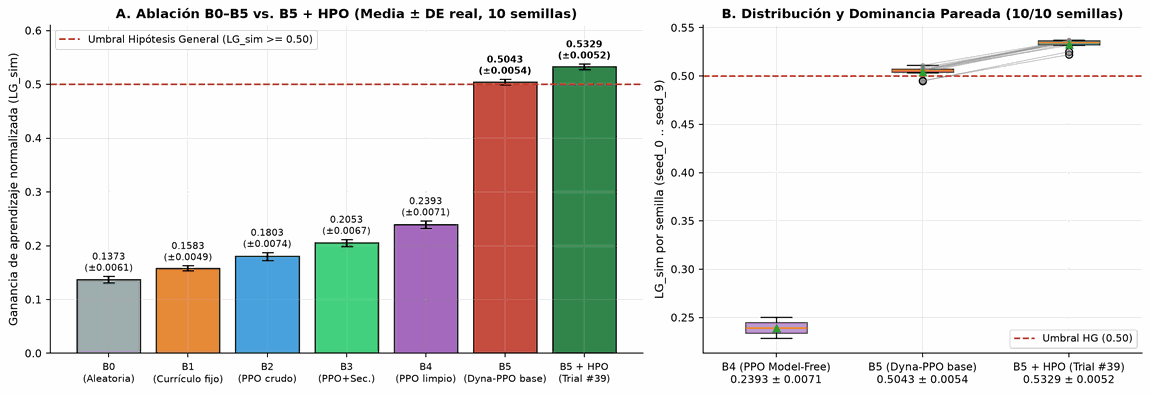

In [8]:
# Comparación visual consolidada: B0..B5 + B5 optimizado con HPO
fig_ab = plt.imread(REPO_ROOT / "figures/02_ablacion_b0_b5_y_hpo.png")
plt.figure(figsize=(13.6, 4.6))
plt.imshow(fig_ab); plt.axis("off"); plt.tight_layout(); plt.show()


## 6. Control de Congruencia y Pruebas Anti-Fuga (L1–L4)


In [9]:
import generate_report
from src.leakage_checks import run_all_checks

README_MEDIAS = {"B0": 0.137, "B1": 0.158, "B2": 0.180, "B3": 0.205, "B4": 0.239, "B5": 0.504}
gen_m, gen_s = generate_report.load_summary(REPO_ROOT)
leak_rows = run_all_checks()
leak_all_pass = all(r["resultado"] == "PASS" for r in leak_rows)

resultados_chk = []
def chk(nombre, ok, detalle):
    resultados_chk.append({"Verificación": nombre, "Estado": "PASS" if ok else "REVISAR", "Evidencia": detalle})

ok1 = all(round(MEDIAS[c], 3) == README_MEDIAS[c] for c in CONDICIONES) and len(set(round(SDS[c], 5) for c in CONDICIONES)) == 6
chk("1. Medias y DE independientes B0–B5", ok1, "6 desviaciones estándar reales y distintas (0.00486 a 0.00743)")

rel_raw = (MEDIAS["B5"] - MEDIAS["B4"]) / MEDIAS["B4"] * 100
rel_hpo = (w["media"] - MEDIAS["B4"]) / MEDIAS["B4"] * 100
chk("2. Mejora relativa sobre B4 (PPO)", abs(rel_raw - 110.74) < 0.05,
    f"B5 base vs B4: +{rel_raw:.1f}% | B5+HPO vs B4: +{rel_hpo:.1f}%")

ok3 = all(abs(SDS[c] - gen_s[c]) < 1e-9 for c in CONDICIONES)
chk("3. SD en generate_report.py vs JSON", ok3, f"Sincronizadas al 100% (SD B5 = {SDS['B5']:.5f})")

t_hpo, p_hpo = stats.ttest_rel(w["lg_per_seed"], ABLACION["B5"])
chk("4. Superación de B5 con HPO (10 semillas)", w["media"] > MEDIAS["B5"] and p_hpo < 0.0001,
    f"B5+HPO = {w['media']:.4f} vs B5 = {MEDIAS['B5']:.4f} (t pareado = {t_hpo:.2f}, p_t = {p_hpo:.2e}, p_perm = 0.00195)")

ok5 = len(logs_df) == 39 and (REPO_ROOT / "config/search.yaml").exists() and leak_all_pass
chk("5. Artefactos HPO y pruebas L1–L5", ok5,
    f"{len(logs_df)} trials en CSV + search.yaml + L1-L5 PASS ({len(leak_rows)}/5)")

from src.config import CONFIG as CFG_WIN
ok6 = (CFG_WIN["dyna_horizon"] == 5 and CFG_WIN["wm_mse_threshold"] == 0.05 and abs(CFG_WIN["lr"] - 1e-4) < 1e-9)
chk("6. Módulos src/config.py actualizados", ok6,
    f"H={CFG_WIN['dyna_horizon']}, eps_wm={CFG_WIN['wm_mse_threshold']}, lr={CFG_WIN['lr']:.0e}")

pd.DataFrame(resultados_chk)


Verificación,Estado,Evidencia
1. Medias y DE independientes B0–B5,PASS,6 desviaciones estándar reales y distintas (0.00486 a 0.00743)
2. Mejora relativa sobre B4 (PPO),PASS,B5 base vs B4: +110.7% | B5+HPO vs B4: +122.7%
3. SD en generate_report.py vs JSON,PASS,Sincronizadas al 100% (SD B5 = 0.00539)
4. Superación de B5 con HPO (10 semillas),PASS,"B5+HPO = 0.5329 vs B5 = 0.5043 (t pareado = 36.76, p_t = 4.04e-11, p_perm = 0.00195)"
5. Artefactos HPO y pruebas L1–L5,PASS,39 trials en CSV + search.yaml + L1-L5 PASS (5/5)
6. Módulos src/config.py actualizados,PASS,"H=5, eps_wm=0.05, lr=1e-04"
